# 04 — Embedding Similarity & Validation-Only Threshold Tuning

This notebook encodes scientific mentions with `sentence-transformers/all-MiniLM-L6-v2` (cached in `outputs/cache/`), compares threshold-graph **Connected Components** vs. cosine **Agglomerative Clustering (average linkage)** strictly on the **Validation** split across thresholds `0.50` to `0.95`, freezes the winning configuration, and inspects predicted Test clusters.


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
print("Repository working directory ready:", ROOT.name)


Repository working directory ready: tusk 4


In [2]:
from src.data_loader import load_config
from src.embedding_model import MentionEmbedder
from src.threshold_tuning import select_best_threshold

cfg = load_config(ROOT / "config.yaml")
metrics_dir = ROOT / cfg["paths"]["metrics_dir"]
val_tuning_df = pd.read_csv(metrics_dir / "validation_threshold_results.csv")
display(val_tuning_df.head(10))

for algo in val_tuning_df["algorithm"].unique():
    sub = val_tuning_df[val_tuning_df["algorithm"] == algo]
    best = select_best_threshold(sub, tie_breaker=cfg["threshold_tuning"]["tie_breaker"])
    print(f"Best on Validation ({algo}): threshold={best['threshold']:.2f}, P={best['precision']:.4f}, R={best['recall']:.4f}, F1={best['f1']:.4f}")


,threshold,algorithm,precision,recall,f1,tp,fp,fn,num_gold_clusters,num_pred_clusters,num_mentions,num_topics
0,0.50,connected_components,0.179053,0.988298,0.303178,17313,79379,205,1747,244,4873,100
1,0.52,connected_components,0.185438,0.985272,0.312130,17260,75817,258,1747,267,4873,100
2,0.54,connected_components,0.192577,0.974826,0.321619,17077,71599,441,1747,304,4873,100
3,0.56,connected_components,0.201904,0.973456,0.334441,17053,67408,465,1747,352,4873,100
4,0.58,connected_components,0.218910,0.965978,0.356933,16922,60379,596,1747,408,4873,100
5,0.60,connected_components,0.226579,0.963923,0.366911,16886,57640,632,1747,461,4873,100
6,0.62,connected_components,0.238472,0.959185,0.381978,16803,53658,715,1747,517,4873,100
7,0.64,connected_components,0.255097,0.958557,0.402956,16792,49034,726,1747,576,4873,100
8,0.66,connected_components,0.267733,0.954961,0.418215,16729,45755,789,1747,643,4873,100
9,0.68,connected_components,0.281009,0.948225,0.433538,16611,42501,907,1747,714,4873,100


Best on Validation (connected_components): threshold=0.84, P=0.5941, R=0.6454, F1=0.6187
Best on Validation (agglomerative): threshold=0.74, P=0.6138, R=0.7075, F1=0.6573


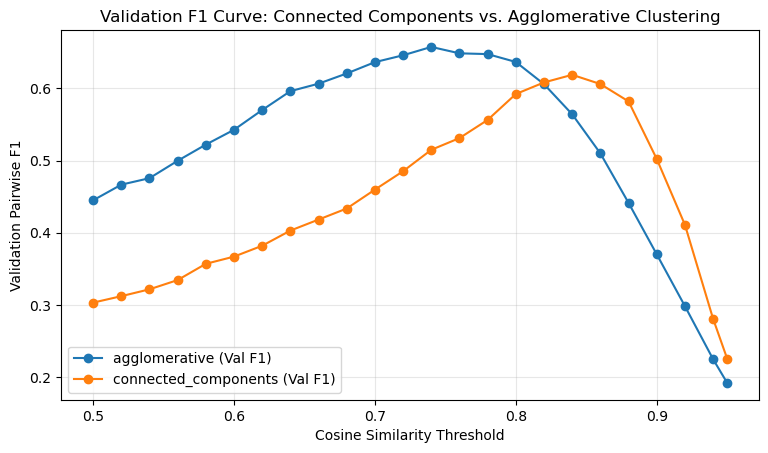

In [3]:
# Compare connected_components vs agglomerative validation F1 curves
fig, ax = plt.subplots(figsize=(9, 4.8))
for algo, grp in val_tuning_df.groupby("algorithm"):
    ax.plot(grp["threshold"], grp["f1"], marker="o", label=f"{algo} (Val F1)")
ax.set_xlabel("Cosine Similarity Threshold")
ax.set_ylabel("Validation Pairwise F1")
ax.set_title("Validation F1 Curve: Connected Components vs. Agglomerative Clustering")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


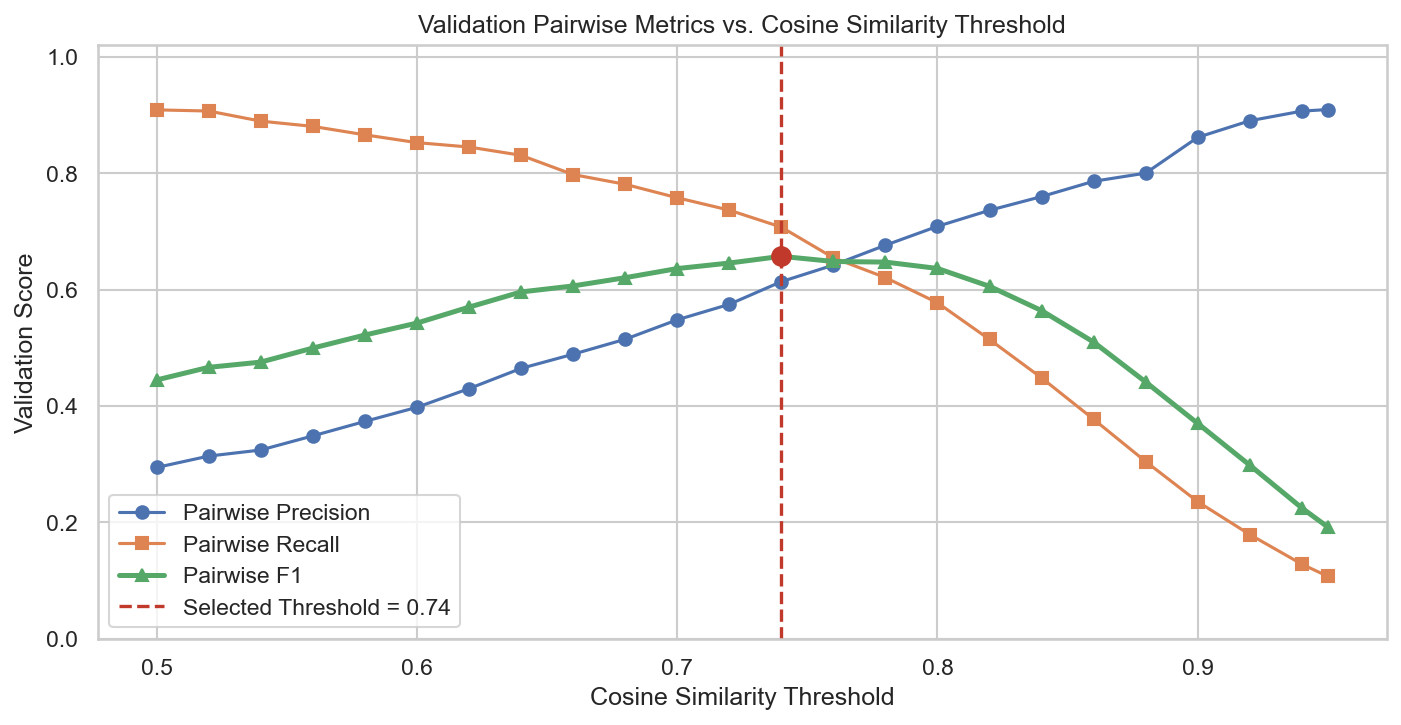

In [4]:
# Display saved threshold curve figure for the winning model
fig_path = ROOT / cfg["paths"]["figures_dir"] / "04_validation_f1_vs_threshold.png"
if fig_path.exists():
    display(Image(filename=str(fig_path)))


In [5]:
# Inspect example predicted clusters on Test
test_emb_preds = pd.read_csv(ROOT / cfg["paths"]["clusters_dir"] / "embedding_clusters.csv")
multi_cids = test_emb_preds.groupby("pred_cluster_id").filter(lambda g: len(g) >= 4)["pred_cluster_id"].unique()[:4]
display(test_emb_preds[test_emb_preds["pred_cluster_id"].isin(multi_cids)][
    ["topic_id", "mention_text", "normalized_text", "gold_cluster_id", "pred_cluster_id"]
].sort_values(["pred_cluster_id", "topic_id"]))


,topic_id,mention_text,normalized_text,gold_cluster_id,pred_cluster_id
0,842,batch normalization,batch normalization,test::t842::c22,test::t842::agglomerative_0
1,842,Batch Normalization,batch normalization,test::t842::c22,test::t842::agglomerative_0
5,842,Batch Normalization configuration,batch normalization configuration,test::t842::c22,test::t842::agglomerative_0
6,842,batch normalization process,batch normalization process,test::t842::c22,test::t842::agglomerative_0
11,842,batch normalization,batch normalization,test::t842::c22,test::t842::agglomerative_0
12,842,batch - normalization,batch - normalization,test::t842::c22,test::t842::agglomerative_0
13,842,Batch Normalization Layers,batch normalization layers,test::t842::c22,test::t842::agglomerative_0
14,842,batch normalization layers,batch normalization layers,test::t842::c22,test::t842::agglomerative_0
20,842,switchable batch normalization,switchable batch normalization,test::t842::c15,test::t842::agglomerative_0
2,842,channel normalization,channel normalization,test::t842::c21,test::t842::agglomerative_1
